In [1]:
from pprint import pprint
import os, sys
from pathlib import Path
from typing import Optional, Any, Callable, Union
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from copy import deepcopy
from collections import defaultdict
from time import perf_counter

# import wandb
# from dask.distributed import Client, as_completed
import networkx as nx
import torch
import numpy as np
import numpy.linalg as npla
import pandas as pd
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    precision_recall_curve, auc, roc_curve
    )
from sklearn.model_selection import KFold
from tqdm import tqdm
import optuna
import omegaconf as oc
from omegaconf import OmegaConf
import matplotlib.pyplot as plt

from t_regs.multilinear_ops.tensor_products import multi_mode_product as mmp
from t_regs.solvers.manifold.minimax_problem import MinimaxProblem
from t_regs.solvers.manifold.rada import RADA_RGD
from t_regs.models.regression.tucker_nn_regressor import TuckerRegressor
from t_regs.models.regression.tucker_nn_bcd_v2 import TuckerRegressorBCD
from t_regs.synthetic_data.generate_lr_data import (
    generate_sparse_low_tucker_rank_tensor,
    generate_low_rank_data,
    generate_smooth_low_tucker_rank_tensor
    )
from t_regs.synthetic_data.regression import (
    generate_tensor_regression_predictors,
    generate_tensor_regression_response
    )

path = Path().cwd().parent.parent.parent
sys.path.append(str(path))

from experiments.synthetic.hp_study_utils import get_model, get_data
from experiments.synthetic.synthetic_study_utils import (
    register_resolvers,
    init_rada_rgd
    )

register_resolvers()

In [2]:
def search_l1_path(
    base_model: TuckerRegressorBCD,
    mode: int,
    lda_range: list[float],
    X, y, X_val, y_val,
    rada_cfg,
    verbosity = 1,
    use_full_solver: bool = False,
    return_best: bool = False,
    ):
    path_model = deepcopy(base_model)
    results = defaultdict(list)
    results['baseline'] = {
        't_score': base_model._t_score,
        'v_score': base_model._v_score,
        't_loss': base_model._t_loss,
        'v_loss':  0.0 if base_model._v_loss is None else base_model._v_loss,
    }
    best_model = deepcopy(base_model)
    best_v_score = 0.0 if base_model._v_score is None else base_model._v_score
    best_lda = 0.0
    for i, lda in enumerate(lda_range):
        ts = perf_counter()
        if use_full_solver:
            path_model = deepcopy(base_model)
        if verbosity:
            print(f"Running iteration {i+1}/{len(lda_range)} with lda={lda:.3e}")
        path_model.ldas[mode-1] = float(lda)
        x0 = path_model.tucker_regressor.Us[mode-1]
        dim = x0.numel()
        n, r = x0.shape[0],x0.shape[1]
        rada_cfg.R = float(lda*dim**0.5)
        rada_cfg.beta1 = 0.1*n*r**0.5
        rada_rgd_solver = RADA_RGD(**rada_cfg)
        path_model.subproblem_solvers[f'U_{mode}'] = rada_rgd_solver
        if use_full_solver:
            # path_model.init_with_hosvd_of_grad = False
            path_model.fit(X, y, X_val=X_val, y_val=y_val)
        else:
            problem, covariate_transform = path_model._initialize_U_subproblem(
            use_dloader=False,
            mode=mode,
            X=X,
            y=y,
            X_val=X_val,
            y_val=y_val,
            save_score_to_self=True,
            )
            rada_result = rada_rgd_solver.solve(
                problem,
                x0=x0.detach().clone(),
                y0=path_model.solver_results[f'U_{mode}'].point.y,
            )
            path_model.solver_results[f'U_{mode}'] = rada_result
            path_model.tucker_regressor.Us[mode-1].requires_grad = False
            path_model.tucker_regressor.Us[mode-1].copy_(
                rada_result.point.x.data
            )
        # results['U'].append(path_model.tucker_regressor.Us[mode-1].clone().detach())
        # results['U_sparsity'].append(
        #     float(rada_result.point.x.data.numel() - (rada_result.point.x.data != 0).sum()))
        # results['U_sparsity~'].append(float(rada_result.point.x.data.numel() - (rada_result.point.x.abs() > 1e-6).sum()))
        results['time'].append(perf_counter() - ts)
        results['v_score'].append(path_model._v_score)
        results['t_score'].append(path_model._t_score)
        results['v_loss'].append(float(path_model._v_loss))
        results['t_loss'].append(path_model._t_loss)
        # results['grad_norm'].append(float(rada_result.gradient_norm))
        results['lda'].append(float(lda))

        if path_model._v_score > best_v_score:
            best_model = deepcopy(path_model)
            best_lda = float(lda)
    if return_best:
        results['best_model'] = best_model
        results['best_lda'] = best_lda
    return results

In [3]:
def search_ridge_path(
    base_model: TuckerRegressorBCD,
    ridge_path: list[float],
    X, y, X_val, y_val,
    rada_cfg,
    verbosity=1,
    ):
    path_model = deepcopy(base_model)
    results = defaultdict(list)
    results['baseline'] = {
        't_score': base_model._t_score,
        'v_score': base_model._v_score,
        't_loss': base_model._t_loss,
        'v_loss': base_model._v_loss,
    }

    for i, tau in enumerate(ridge_path):
        ts = perf_counter()
        # path_model = deepcopy(path_model)
        if verbosity:
            print(f"Running iteration {i+1}/{len(ridge_path)} with tau={tau:.3e}")
        path_model.tau = tau
        dim = path_model.tucker_regressor.core.numel()
        problem, covariate_transform = path_model._initialize_C_subproblem(
            use_dloader=False,
            X=X,
            y=y
        )
        lda_core = path_model.lda_core
        rada_cfg.R = float(lda_core*dim**0.5)
        rada_cfg.beta1 = 0.01*dim # float(lda*dim)/100
        rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
        rada_result = rada_rgd_solver.solve(
            problem,
            x0=path_model.tucker_regressor.core.detach().clone(),
            # y0=path_model.solver_results['C'].point.y,
        )
        path_model.solver_results['C'] = rada_result
        path_model.tucker_regressor.core.requires_grad = False
        path_model.tucker_regressor.core.copy_(
            rada_result.point.x.data
        )

        results['results'].append(rada_result.point.x.data.clone().detach())
        results['sparsity'].append(float(rada_result.point.x.data.numel() - (rada_result.point.x.data != 0).sum()))
        results['sparsity~'].append(float(rada_result.point.x.data.numel() - (rada_result.point.x.abs() > 1e-6).sum()))
        results['time'].append(perf_counter() - ts)
        results['grad_norm'].append(float(rada_result.gradient_norm))
        results['tau'].append(float(tau))
        results['lda_core'].append(float(lda_core))

        with torch.no_grad():
            X_prime = covariate_transform(X)
            eta = path_model.tucker_regressor.functional_core(
                core=rada_result.point.x,
                x=X_prime)
            train_loss = path_model.tucker_regressor.loss_fn(eta, y)
            train_score = path_model.tucker_regressor.score(eta, y)

            X_val_prime = covariate_transform(X_val)
            eta = path_model.tucker_regressor.functional_core(
                core=rada_result.point.x,
                x=X_val_prime)
            val_loss = path_model.tucker_regressor.loss_fn(eta, y_val)
            val_score = path_model.tucker_regressor.score(eta, y_val)

        results['v_score'].append(val_score)
        results['t_score'].append(train_score)
        results['v_loss'].append(val_loss)
        results['t_loss'].append(train_loss)
    return results


In [ ]:
seed = 3
conf = OmegaConf.load('./../configs/study_0_a.yaml')
conf.rada_rgd_cfg.eps = 1e-10
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [16, 16, 16]
conf.data.expanded = True
conf.data.n_train = 1200
conf.data.seed = seed
conf.model_cfg.regressor.feature_ranks[0] = 3
conf.model_cfg.regressor.feature_ranks[1] = 3
conf.model_cfg.regressor.feature_ranks[2] = 3
conf.model_cfg.verbosity = 2
conf.model_cfg.max_it= 100
conf.model_cfg.max_time= 1000000
conf.rada_rgd_cfg.Tk = 100
pprint(conf.model_cfg)

# torch.manual_seed(1)

conf.data.seed= seed
data = get_data(conf.data)
conf.model_cfg.init_with_hosvd_of_grad = True
conf.model_cfg.max_it = 100
conf.model_cfg.regressor.seed = seed
model = get_model(conf.model_cfg, 'cuda:2')
data['X'] = data['X'].to(model.device)
data['y'] = data['y'].to(model.device)
X_train, X_val = data['X'][300:], data['X'][:300]
y_train, y_val = data['y'][300:].reshape(-1, 1), data['y'][:300].reshape(-1, 1)
model.fit(
    X_train,
    y_train,
    X_val=X_val,
    y_val=y_val,
    seed=seed
)

{'model_name': 'LR-Tucker', 'regressor': {'regression_type': 'logistic', 'feature_dims': '${data.dims}', 'feature_ranks': [3, 3, 3], 'feature_manifolds': ['${Steifel:${..feature_dims[0]}, ${..feature_ranks[0]}, ${...device}}', '${Steifel:${..feature_dims[1]}, ${..feature_ranks[1]}, ${...device}}', '${Steifel:${..feature_dims[2]}, ${..feature_ranks[2]}, ${...device}}']}, 'tau': 0.0, 'ldas': [0.0, 0.0, 0.0], 'lda_core': 0.0, 'thetas': [0.0, 0.0, 0.0], 'Ds': None, 'Ls': [None, None, None], 'subproblem_solvers': {'U_1': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[0]},${mul:${data.dims[0]},${..regressor.feature_ranks[0]}}}', 'U_2': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[1]},${mul:${data.dims[1]},${..regressor.feature_ranks[1]}}}', 'U_3': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[2]},${mul:${data.dims[2]},${..regressor.feature_ranks[2]}}}', 'C': '${init_rada_rgd:${rada_rgd_cfg},${..lda_core},${mul_list:${..regressor.feature_ranks}}}'}, 'dataloader_cfg': None, 'main_algorithm': 'BCD_RADA_RGD

: 

In [5]:

conf.model_cfg.min_gradient_norm = 1e-3
# model = get_model(conf.model_cfg, 'cuda:2')
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 10000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-10
lda_range = np.logspace(-7, 3, 20)[:-1]
ridge_results = search_ridge_path(
    model,
    lda_range,
    X_train, y_train, X_val, y_val,
    rada_rgd_cfg,
    verbosity=1,
    )

imax = np.argmax(ridge_results['v_score'])
tau_max = ridge_results['tau'][imax]
print(f"tau_max = {tau_max}")
print(f"v_score = {ridge_results['v_score'][imax]}")

Running iteration 1/19 with tau=1.000e-07
Running iteration 2/19 with tau=3.360e-07
Running iteration 3/19 with tau=1.129e-06
Running iteration 4/19 with tau=3.793e-06
Running iteration 5/19 with tau=1.274e-05
Running iteration 6/19 with tau=4.281e-05
Running iteration 7/19 with tau=1.438e-04
Running iteration 8/19 with tau=4.833e-04
Running iteration 9/19 with tau=1.624e-03
Running iteration 10/19 with tau=5.456e-03
Running iteration 11/19 with tau=1.833e-02
Running iteration 12/19 with tau=6.158e-02
Running iteration 13/19 with tau=2.069e-01
Running iteration 14/19 with tau=6.952e-01
Running iteration 15/19 with tau=2.336e+00
Running iteration 16/19 with tau=7.848e+00
Running iteration 17/19 with tau=2.637e+01
Running iteration 18/19 with tau=8.859e+01
Running iteration 19/19 with tau=2.976e+02
tau_max = 0.005455594781168515
v_score = 0.6566666666666666


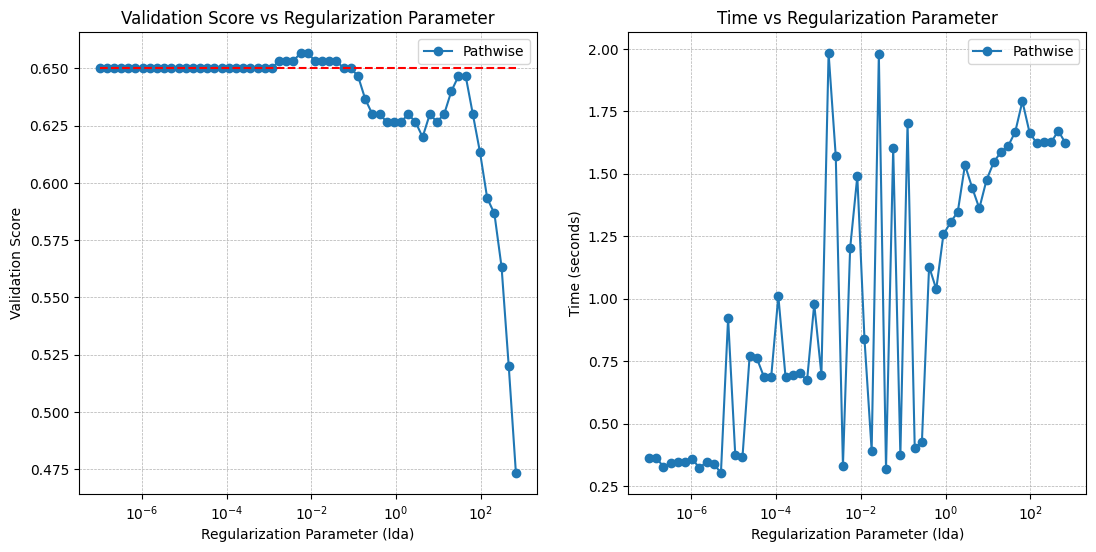

In [6]:
results = ridge_results
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes = axes.flatten()
axes[0].plot(results['tau'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'],
               xmin=results['tau'][0], xmax=results['tau'][-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['tau'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
# axes[2].loglog(results['lda'], results['grad_norm'], label='Pathwise', marker='o')
# # axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
# axes[2].set_xscale('log')
# axes[2].set_xlabel('Regularization Parameter (lda)')
# axes[2].set_ylabel('Gradient Norm')
# axes[2].set_title('Gradient Norm vs Regularization Parameter')
# axes[2].legend()
# axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

In [ ]:
# conf.model_cfg.min_gradient_norm = 1e-2
# model = get_model(conf.model_cfg, 'cuda:2')
model.tau = 0.0 # tau_max # 4.25e-2
model.max_it = 400
model.min_gradient_norm = 1e-3
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 10000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-8
lda_range = np.logspace(-3, 1, 10)
results = search_l1_path(
    model, 1, lda_range,
    X_train, y_train, X_val, y_val,
    rada_rgd_cfg,
    verbosity = 1,
    use_full_solver=True,
)


Running iteration 1/10 with lda=1.000e-03
Initializing with the HoSVD of the gradient evaluated at 0
Starting BCD_RGD Solver for Tucker Regression
Hyper-parameters:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.001, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    Train score    Val score    Cost                Gradient norm    U_1 grad norm    U_2 grad norm    U_3 grad norm    C grad norm    
---------    -----------    ---------    ----------------    -------------    -------------    -------------    -------------    -----------    
  1          0.8589         0.6600       3.7961221656e-01    1.0633e+04       6.5541e-02       3.8633e-02       6.8642e-13       1.0633e+04     
  2          0.9167         0.6533       2.4061179741e-01    1.4079e+03       6.8988e-02       4.1290e-02       5.7806

KeyboardInterrupt: 

: 

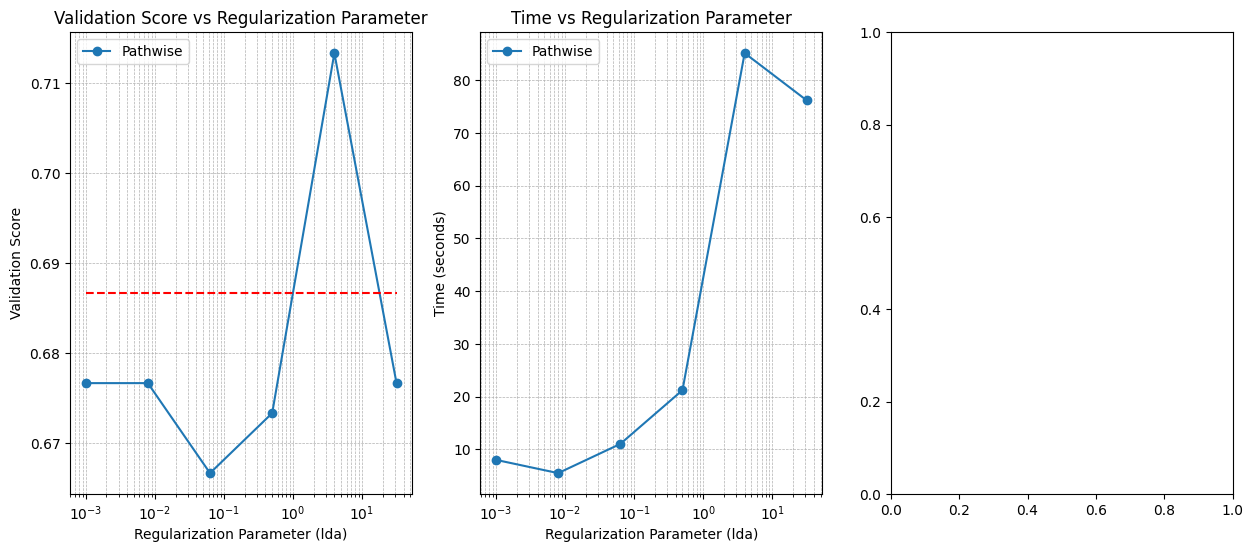

In [ ]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes = axes.flatten()
axes[0].plot(results['lda'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'],
               xmin=results['lda'][0], xmax=results['lda'][-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
# axes[2].loglog(results['lda'], results['grad_norm'], label='Pathwise', marker='o')
# # axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
# axes[2].set_xscale('log')
# axes[2].set_xlabel('Regularization Parameter (lda)')
# axes[2].set_ylabel('Gradient Norm')
# axes[2].set_title('Gradient Norm vs Regularization Parameter')
# axes[2].legend()
# axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

In [10]:
i = np.argmax(results['v_score'])
lda_best = results['lda'][i]
v_score_best = results['v_score'][i]
improved =  v_score_best > results['baseline']['v_score']
    

True

In [48]:

rada_rgd = conf.rada_rgd_cfg.copy()
rada_rgd.verbosity = 0
rada_rgd.Tk= 100
rada_rgd.max_it = 10000
rada_rgd.c1 = 0.1
rada_rgd.rho = 1.5 # 2.5
rada_rgd.eps = 1e-10

modes = [1]#,2,3]
lda_ranges = [np.logspace(-3, 2, 16) for _ in modes]
search_results = {}

for i, m in enumerate(modes):
    result = search_l1_path(
        model, m, lda_ranges[i],
        X_train, y_train, X_val, y_val,
        rada_rgd,
        verbosity = 1,
        use_full_solver=False,
    )
    search_results[m] = result

Running iteration 1/16 with lda=1.000e-03
Running iteration 2/16 with lda=2.154e-03
Running iteration 3/16 with lda=4.642e-03
Running iteration 4/16 with lda=1.000e-02
Running iteration 5/16 with lda=2.154e-02
Running iteration 6/16 with lda=4.642e-02
Running iteration 7/16 with lda=1.000e-01
Running iteration 8/16 with lda=2.154e-01
Running iteration 9/16 with lda=4.642e-01
Running iteration 10/16 with lda=1.000e+00
Running iteration 11/16 with lda=2.154e+00
Running iteration 12/16 with lda=4.642e+00
Running iteration 13/16 with lda=1.000e+01
Running iteration 14/16 with lda=2.154e+01
Running iteration 15/16 with lda=4.642e+01
Running iteration 16/16 with lda=1.000e+02


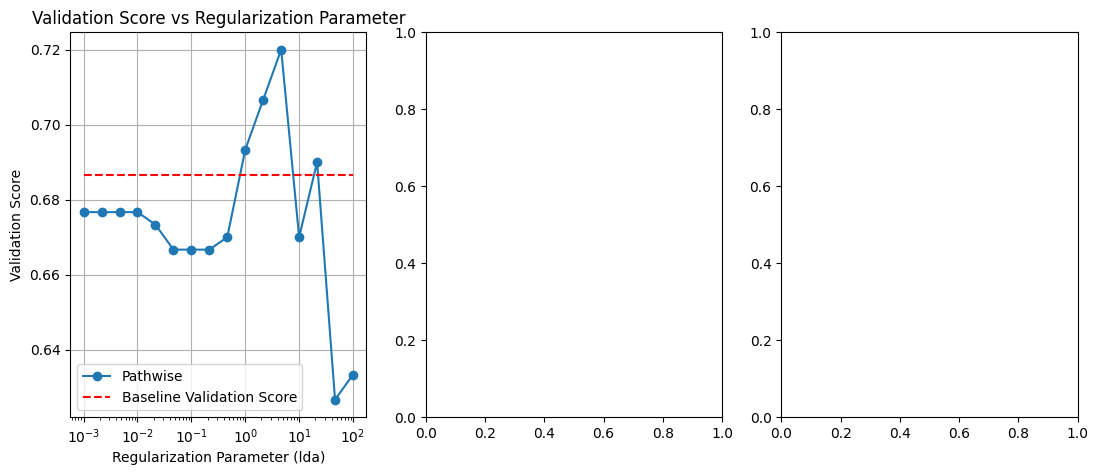

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes = axes.flatten()
for i,m in enumerate(modes):
    axes[i].plot(search_results[m]['lda'], search_results[m]['v_score'], label='Pathwise', marker='o')
    axes[i].set_xscale('log')
    axes[i].set_xlabel('Regularization Parameter (lda)')
    axes[i].set_ylabel('Validation Score')
    axes[i].set_title('Validation Score vs Regularization Parameter')
    axes[i].hlines(search_results[m]['baseline']['v_score'],
                xmin=search_results[m]['lda'][0], xmax=search_results[m]['lda'][-1], 
                colors='r', linestyles='dashed', label='Baseline Validation Score')
    axes[i].legend()
    axes[i].grid()

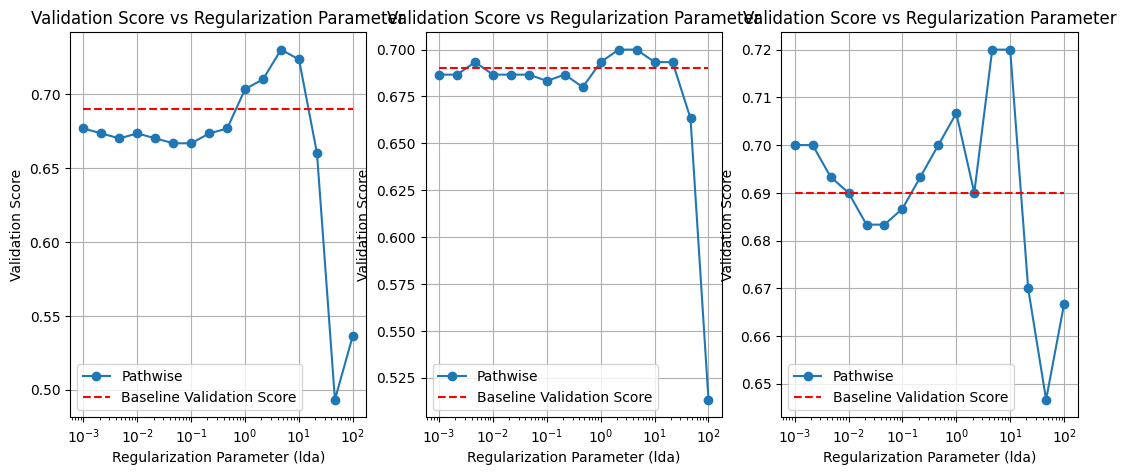

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes = axes.flatten()
for i,m in enumerate(modes):
    axes[i].plot(search_results[m]['lda'], search_results[m]['v_score'], label='Pathwise', marker='o')
    axes[i].set_xscale('log')
    axes[i].set_xlabel('Regularization Parameter (lda)')
    axes[i].set_ylabel('Validation Score')
    axes[i].set_title('Validation Score vs Regularization Parameter')
    axes[i].hlines(search_results[m]['baseline']['v_score'],
                xmin=search_results[m]['lda'][0], xmax=search_results[m]['lda'][-1], 
                colors='r', linestyles='dashed', label='Baseline Validation Score')
    axes[i].legend()
    axes[i].grid()

In [53]:
rada_rgd = conf.rada_rgd_cfg.copy()
rada_rgd.verbosity = 1
rada_rgd.Tk= 100
rada_rgd.max_it = 10000
rada_rgd.c1 = 0.1
rada_rgd.rho = 1.5 # 2.5
rada_rgd.eps = 1e-10


improved = False
best_ldas = model.ldas
best_Us = [U.data for U in model.tucker_regressor.Us]
for m in modes:
    result = search_results[m]
    i = np.argmax(result['v_score'])
    lda_best = result['lda'][i]
    v_score_best = result['v_score'][i]
    if v_score_best > result['baseline']['v_score']:
        improved = True
        best_ldas[m-1] = lda_best

# b_model = get_model(conf.model_cfg, 'cuda:2')
# b_model.fit(
#     X_train,
#     y_train,
#     X_val=X_val,
#     y_val=y_val,
#     seed=seed
# )

if improved:
    next_model = deepcopy(model)

    for i, mode in enumerate(modes):
        lda = best_ldas[i]
        next_model.ldas[i] = lda
        rada_cfg_n = rada_rgd.copy()
        # next_model.tucker_regressor.Us[i].copy_(
        #         best_Us[i].data
        #     )
        x0 = next_model.tucker_regressor.Us[mode-1]
        dim = x0.numel()
        n, r = x0.shape[0], x0.shape[1]
        rada_cfg_n.R = float(lda*dim**0.5)
        rada_cfg_n.beta1 = 0.1*n*r**0.5
        next_model.subproblem_solvers[f'U_{mode}'] = RADA_RGD(**rada_cfg_n)

        next_model.init_with_hosvd_of_grad = False
        next_model.fit(X_train, y_train, X_val=X_val, y_val=y_val)

Starting BCD_RGD Solver for Tucker Regression
Hyper-parameters:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [4.6415888336127775, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    Train score    Val score    Cost                Gradient norm    U_1 grad norm    U_2 grad norm    U_3 grad norm    C grad norm    
---------    -----------    ---------    ----------------    -------------    -------------    -------------    -------------    -----------    
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 266 iterations, 57.125 seconds.

  1          0.9400         0.6967       2.8225264940e+01    1.0128e+03       2.2316e+01       9.9753e+00       3.0642e-11       1.0128e+03     
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 35 iterations, 7.270 seconds.

  2          0

KeyboardInterrupt: 

ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

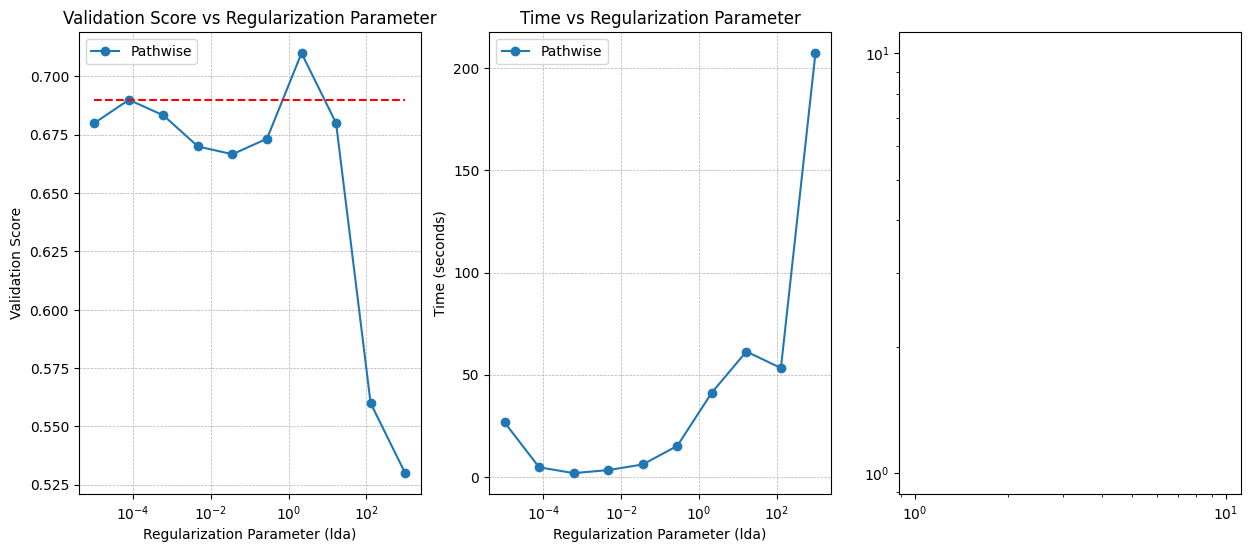

In [11]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes = axes.flatten()
axes[0].plot(results['lda'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'],
               xmin=results['lda'][0], xmax=results['lda'][-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(results['lda'], results['grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

In [ ]:
from copy import deepcopy
from collections import defaultdict
from time import perf_counter
from typing import overload

from torch.utils.data import Dataset

from t_regs.utils import printer
from t_regs.solvers.manifold.rada import RADA_RGD
from t_regs.models.regression.tucker_nn_bcd_v2 import TuckerRegressorBCD
from t_regs.solvers.manifold.minimax_problem import MinimaxProblem
from t_regs.models.regression.tucker_nn_regressor import (
    TuckerRegressor,
    TuckerCovariateTransform
    )


class TuckerBCDRegularizerPathStudy:

    def __init__(
        self,
        parameter: str,
        reg_path: list[float],
        rada_cfg: dict[str, Any],
        mode: Optional[int] = None,
        verbosity: Optional[int] = 1
        ):
        self.parameter = parameter
        self.reg_path = reg_path
        self.rada_cfg = rada_cfg
        self.mode = mode
        self.verbosity = verbosity
        self.log = None

    @overload
    def __call__(
        self,
        base_model: TuckerRegressorBCD,
        X: torch.Tensor,
        y: torch.Tensor,
        X_val: torch.Tensor,
        y_val: torch.Tensor,
        ):
        pass

    @overload
    def __call__(
        self,
        base_model: TuckerRegressorBCD,
        dataset: Dataset,
        val_dataset: Dataset,
        ):
        pass

    def __call__(
        self,
        base_model: TuckerRegressorBCD,
        **kwargs
        ):
        printer = self._init_printer(base_model)
        printer.print_header()
        X = kwargs.get('X', None)
        y = kwargs.get('y', None)
        X_val = kwargs.get('X_val', None)
        y_val = kwargs.get('y_val', None)
        dataset = kwargs.get('dataset', None)
        val_dataset = kwargs.get('val_dataset', None)
        use_dloader = X is None
        if base_model._t_loss is None:
            if use_dloader:
                base_model.fit(dataset, val_dataset=val_dataset)
            else:
                base_model.fit(X, y, X_val=X_val, y_val=y_val)
        self._init_log(base_model)
        path_model = deepcopy(base_model)

        best_model = deepcopy(base_model)
        best_score = best_model._v_score
        best_model_reg_params = {
            'tau': best_model.tau,
            'lda_core': best_model.lda_core,
            'thetas': best_model.thetas,
            'ldas': best_model.ldas,
        }
        rada_cfg = deepcopy(self.rada_cfg)
        for i, reg_param in enumerate(self.reg_path):
            ts = perf_counter()
            # path_model = deepcopy(path_model)
            if self.parameter == 'ldas' or self.parameter == 'thetas':
                mode = self.mode
                if self.parameter == 'ldas':
                    path_model.ldas[mode-1] = reg_param
                else:
                    path_model.thetas[mode-1] = reg_param
                lda = path_model.ldas[mode-1]
                x0 = path_model.tucker_regressor.Us[mode-1].detach().clone()
                y0 = (path_model.solver_results[f'U_{mode}'].point.y if i != 0
                      else None)
                dim = path_model.tucker_regressor.Us[mode-1].numel()
                n, r = x0.shape[0], x0.shape[1]
                problem, cov_transform = path_model._initialize_U_subproblem(
                    use_dloader=False,
                    mode=mode,
                    X=X,
                    y=y,
                    X_val=X_val,
                    y_val=y_val,
                    save_score_to_self=True,
                )
                rada_cfg.R = float(lda*dim**0.5)
                rada_cfg.beta1 = float(0.1*n*r**0.5)
                rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
                path_model.subproblem_solvers[f'U_{mode}'] = rada_rgd_solver
                rada_result = rada_rgd_solver.solve(
                    problem,
                    x0=x0,
                    y0=y0,
                )
                path_model.solver_results[f'U_{mode}'] = rada_result
                path_model.tucker_regressor.Us[mode-1].requires_grad = False
                path_model.tucker_regressor.Us[mode-1].copy_(
                    rada_result.point.x.data
                )
                val_score = float(path_model._v_score)
                train_score = float(path_model._t_score)
                val_loss = float(path_model._v_loss)
                train_loss = float(path_model._t_loss)
                if val_score >= best_score:
                    best_model = deepcopy(path_model)
                    best_score = val_score
                    best_model_reg_params = {
                        'tau': best_model.tau,
                        'lda_core': best_model.lda_core,
                        'thetas': best_model.thetas,
                        'ldas': best_model.ldas,
                    }
                    self.log['improved'] = True
            elif self.parameter == 'tau' or self.parameter == 'lda_core':
                if self.parameter == 'tau':
                    path_model.tau = reg_param
                else:
                    path_model.lda_core = reg_param
                dim = path_model.tucker_regressor.core.numel()
                problem, cov_transform = path_model._initialize_C_subproblem(
                    use_dloader=use_dloader,
                    X=X,
                    y=y,
                    # X_val=X_val,
                    # y_val=y_val,
                    dataset=dataset
                )
                rada_cfg = deepcopy(self.rada_cfg)
                lda_core = path_model.lda_core
                rada_cfg.R = float(lda_core*dim**0.5)
                # rada_cfg.beta1 = 0.01*dim # float(lda*dim)/100
                rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
                path_model.subproblem_solvers['C'] = rada_rgd_solver
                rada_result = rada_rgd_solver.solve(
                    problem,
                    x0=path_model.tucker_regressor.core.detach().clone(),
                    # y0=path_model.solver_results['C'].point.y,
                )
                path_model.solver_results['C'] = rada_result
                path_model.tucker_regressor.core.requires_grad = False
                path_model.tucker_regressor.core.copy_(
                    rada_result.point.x.data
                )

                with torch.no_grad():
                    X_prime = cov_transform(X)
                    eta = path_model.tucker_regressor.functional_core(
                        core = rada_result.point.x,
                        x = X_prime
                        )
                    train_loss= float(
                        path_model.tucker_regressor.loss_fn(eta, y)
                        )
                    train_score = float(
                        path_model.tucker_regressor.score(eta, y)
                        )

                    X_val_prime = cov_transform(X_val)
                    eta = path_model.tucker_regressor.functional_core(
                        core=rada_result.point.x,
                        x=X_val_prime
                        )
                    val_loss = float(
                        path_model.tucker_regressor.loss_fn(eta, y_val)
                        )
                    val_score=float(path_model.tucker_regressor.score(eta, y_val))
                path_model._v_score = val_score
                path_model._v_loss = val_loss
                path_model._t_score = train_score
                path_model._t_loss = train_loss

            else:
                raise ValueError(f"Unknown parameter: {self.parameter}")

            grad_norm = float(rada_result.gradient_norm)
            tspent = perf_counter() - ts
            num_iter = rada_result.iterations
            term_reason = rada_result.stopping_criterion
            columns = [i, reg_param, train_score, val_score, train_loss,
                       val_loss, grad_norm, tspent, num_iter, term_reason]
            printer.print_row(columns)

            self._add_log_entry(*columns)
            if val_score >= best_score:
                best_model = deepcopy(path_model)
                best_score = val_score
                best_model_reg_params = {
                    'tau': best_model.tau,
                    'lda_core': best_model.lda_core,
                    'thetas': best_model.thetas,
                    'ldas': best_model.ldas,
                }
                self.log['improved'] = True

        return best_model, best_model_reg_params, self.log

    def _init_printer(self, base_model: TuckerRegressorBCD):
        if self.verbosity:
            msg = f"Starting regularization path study for parameter: {self.parameter}"
            msg += f" mode: {self.mode}" if self.mode is not None else ""
            print(msg)
            # TODO: Output base model hyperparameters & baseline scores.
            if self.verbosity >=3:
                print(f"RADA RGD configuration: {self.rada_cfg}")
            if self.verbosity >= 2:
                print(f"Base model configuration:")
                pprint(base_model.hyperparameters)
            iteration_format_length = int(np.log10(len(self.reg_path))) + 1
            lent = int(np.log10(self.rada_cfg.max_it)) + 1
            columns = [
                ("Iteration", f"{iteration_format_length}d"),
                (self.parameter, ".4e"),
                ("Train Score", ".4f"),
                ("Val Score", ".4f"),
                ("Train Loss", ".4e"),
                ("Val Loss", ".4e"),
                ("Grad Norm", ".4e"),
                ("Time (s)", ".2f"),
                ("Num. Iter.", f"{lent}d"),
                ("Termination Reason", ""),
            ]
            column_printer = printer.ColumnPrinter(columns=columns)
        else:
            column_printer = printer.VoidPrinter()
        return column_printer

    def _init_log(self, base_model: TuckerRegressorBCD):
        self.log = {
            'baseline': {
                'train_score': float(base_model._t_score),
                'val_score': float(base_model._v_score),
                'train_loss': float(base_model._t_loss),
                'val_loss': float(base_model._v_loss),
            },
            'results': defaultdict(list),
            'param': self.parameter,
            'mode': self.mode,
            'reg_path': self.reg_path,
            'improved': False,
        }

    def _add_log_entry(self,
        iteration, reg_param, train_score, val_score, train_loss,
        val_loss, grad_norm, tspent, num_iter, term_reason,
        **kwargs
        ):
        self.log['results']['iteration'].append(iteration)
        self.log['results']['reg_param'].append(reg_param)
        self.log['results']['train_score'].append(train_score)
        self.log['results']['val_score'].append(val_score)
        self.log['results']['train_loss'].append(train_loss)
        self.log['results']['val_loss'].append(val_loss)
        self.log['results']['grad_norm'].append(grad_norm)
        self.log['results']['time'].append(tspent)
        self.log['results']['num_iter'].append(num_iter)
        if self.verbosity > 1:
            self.log['results']['term_reason'].append(term_reason)
        for key, value in kwargs.items():
            self.log['iterations'][key].append(value)

    def plot(self, extra_metrics: list[str] = []):
        num_metrics = 1+len(extra_metrics)
        fig, axes = plt.subplots(1, num_metrics, figsize=(7*num_metrics, 6))
        if num_metrics == 1:
            axes = [axes]
        axes[0].semilogx(self.log['results']['reg_param'],
                         self.log['results']['val_score'],
                         marker='o', label='Validation')
        axes[0].semilogx(self.log['results']['reg_param'],
                         self.log['results']['train_score'],
                         marker='o', label='Training')
        axes[0].set_xscale('log')
        axes[0].set_xlabel(f'Regularization Parameter ({self.parameter})')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Score vs Regularization Parameter')
        axes[0].legend()
        axes[0].hlines(self.log['baseline']['val_score'],
                    xmin=self.log['reg_path'][0],
                    xmax=self.log['reg_path'][-1], 
                    colors='r', linestyles='dashed',
                    label='Baseline Validation Score')
        axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)

        for i in range(1, num_metrics):
            mname = extra_metrics[i-1]
            axes[i].semilogx(self.log['results']['reg_param'],
                         self.log['results'][mname], marker='o')
            axes[i].set_xscale('log')
            axes[i].set_xlabel(f'Regularization Parameter ({self.parameter})')
            axes[i].set_ylabel(mname)
            axes[i].set_title(f'{mname} vs Regularization Parameter')
            axes[i].legend()
            axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)
        return fig, axes